# LIME analysis
Model-agnostic local explanations with LIME for a few flagged orders, compared with production reason codes.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "3_Model").exists():
    ROOT = ROOT.parent
for p in ("3_Model", "3_Model/training", "4_Backend/utils"):
    sys.path.insert(0, str(ROOT / p))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"


In [2]:
from lime.lime_tabular import LimeTabularExplainer
from risk_scoring import RiskScorer
scorer = RiskScorer()
feats = pd.read_csv(ROOT / '2_Data/processed_data/feature_engineered.csv')
test = pd.read_csv(ROOT / '3_Model/saved_models/test_set.csv')
explainer = LimeTabularExplainer(feats[scorer.features].sample(5000, random_state=0).values, feature_names=scorer.features,
    class_names=['legit', 'fraud'], discretize_continuous=True, random_state=0)
predict = lambda a: scorer.model.predict_proba(pd.DataFrame(a, columns=scorer.features))

In [3]:
flagged = test[scorer._scores(test) >= 70].head(3)
for _, row in flagged.iterrows():
    exp = explainer.explain_instance(row[scorer.features].values.astype(float), predict, num_features=5)
    print(row.transaction_id, 'score', scorer._scores(row.to_frame().T)[0])
    for rule, w in exp.as_list(): print(f'   LIME  {w:+.3f}  {rule}')
    for r in scorer.score(row.to_frame().T)[0]['reasons']: print('   SHOWN ', r['text'])
    print()

T0015438 score 100
   LIME  +0.080  high_risk_country > 0.00
   LIME  +0.073  users_per_card > 1.00
   LIME  -0.056  failed_logins <= 0.00
   LIME  +0.055  account_age_days <= 96.89
   LIME  -0.049  26.23 < amount <= 45.44
   SHOWN  Card used by 9 different accounts
   SHOWN  IP location (NG) differs from billing country (US)
   SHOWN  Brand-new account (7.8 days old)
   SHOWN  High-risk country involved

T0001803 score 100
   LIME  +0.154  amount > 81.08
   LIME  +0.114  pages_viewed <= 5.00
   LIME  -0.086  accounts_per_device <= 1.00
   LIME  +0.082  users_per_card > 1.00
   LIME  +0.036  account_age_days <= 96.89
   SHOWN  Went straight to checkout (1 pages viewed)
   SHOWN  New account (3 days old) spending $772.01
   SHOWN  2 login attempts, 1 failed
   SHOWN  Connection through a VPN



T0005328 score 96
   LIME  +0.157  amount > 81.08
   LIME  +0.101  pages_viewed <= 5.00
   LIME  -0.084  accounts_per_device <= 1.00
   LIME  +0.070  users_per_card > 1.00
   LIME  +0.053  account_age_days <= 96.89
   SHOWN  3 login attempts, 2 failed
   SHOWN  IP location (FR) differs from billing country (US)
   SHOWN  Brand-new account (8.9 days old)
   SHOWN  Amount $133.87 is 2.4x this customer's normal spend



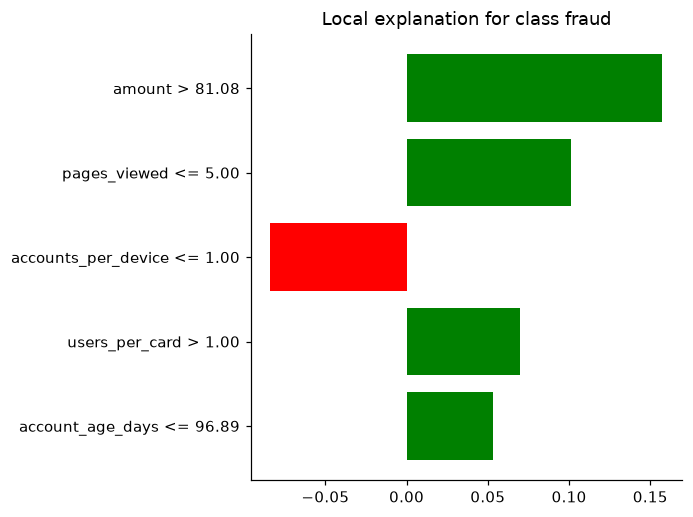

In [4]:
exp.as_pyplot_figure(); plt.tight_layout()